
# Revised Biomass-to-Biofuel Optimization Case Study

This version uses five biomass sources to make the differences between the approaches clearer. It compares a source-order greedy heuristic, an LP relaxation, and a MILP. It also includes one IoT-triggered availability update.

**Scope:** one planning period; five sources; one collection depot; one biofuel plant; one demand node. The model decides biomass quantities and source-level trip counts. It does not assign individual vehicles or optimize route sequences. All source-level numerical data are illustrative.

The conversion yield is retained at 0.22 tonnes of biofuel per tonne of biomass. The illustrative biofuel demand is 3.3 tonnes, requiring 15 tonnes of biomass.


## 1. Install and import

In [1]:
%pip -q install pulp pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:

import math
import pandas as pd
import matplotlib.pyplot as plt
import pulp
print("PuLP:", pulp.__version__)


PuLP: 3.3.2



## 2. Input data

The source data are selected to expose a limitation of the greedy baseline. Source S3 has the lowest approximate delivered cost, but its available quantity is not a multiple of the vehicle payload. The greedy rule fills S3 first and then fills the next source. This can create an additional partly loaded trip.

The MILP can split collection quantities across sources while accounting for whole-trip costs. The data are not intended to represent measured field conditions.


In [3]:

data = pd.DataFrame({
    "source": ["S1", "S2", "S3", "S4", "S5"],
    "availability_t": [10.0, 10.0, 7.0, 7.0, 10.0],
    "purchase_cost_MU_per_t": [8.0, 15.0, 6.0, 13.0, 14.0],
    "one_way_distance_km": [12.0, 14.0, 12.0, 18.0, 13.0],
})

VEHICLE_PAYLOAD_T = 5.0
VEHICLE_COST_MU_PER_KM = 1.2
MAX_TRIPS = 4
BIOFUEL_DEMAND_T = 3.3
CONVERSION_YIELD = 0.22
BIOMASS_REQUIREMENT_T = BIOFUEL_DEMAND_T / CONVERSION_YIELD

data["round_trip_cost_MU"] = (
    2 * data["one_way_distance_km"] * VEHICLE_COST_MU_PER_KM
)
data["delivered_cost_per_t_MU"] = (
    data["purchase_cost_MU_per_t"]
    + data["round_trip_cost_MU"] / VEHICLE_PAYLOAD_T
)

print(f"Required biomass: {BIOMASS_REQUIREMENT_T:.2f} t")
display(data)


Required biomass: 15.00 t


,source,availability_t,purchase_cost_MU_per_t,one_way_distance_km,round_trip_cost_MU,delivered_cost_per_t_MU
0,S1,10.0,8.0,12.0,28.8,13.76
1,S2,10.0,15.0,14.0,33.6,21.72
2,S3,7.0,6.0,12.0,28.8,11.76
3,S4,7.0,13.0,18.0,43.2,21.64
4,S5,10.0,14.0,13.0,31.2,20.24



## 3. Optimization model

For each source \(i\), \(x_i\) is the biomass collected and \(n_i\) is the number of round trips.

\[
\min Z=\sum_i c_i x_i+\sum_i r_i n_i
\]

subject to:

\[
0\leq x_i\leq A_i,\qquad x_i\leq Qn_i
\]

\[
\sum_i x_i\geq B_{\mathrm{req}},\qquad
\sum_i n_i\leq N_{\max}
\]

The LP treats \(n_i\) as continuous. The MILP restricts \(n_i\) to non-negative integers. Biomass quantities remain continuous. The LP is a relaxation and provides a lower bound for this MILP formulation.


In [4]:

def solve_optimization(source_data, integer_trips=False):
    model = pulp.LpProblem(
        "Biomass_MILP" if integer_trips else "Biomass_LP",
        pulp.LpMinimize
    )
    sources = source_data["source"].tolist()
    x = {i: pulp.LpVariable(f"x_{i}", lowBound=0) for i in sources}
    cat = "Integer" if integer_trips else "Continuous"
    n = {i: pulp.LpVariable(f"n_{i}", lowBound=0, cat=cat) for i in sources}

    A = dict(zip(source_data.source, source_data.availability_t))
    c = dict(zip(source_data.source, source_data.purchase_cost_MU_per_t))
    r = dict(zip(source_data.source, source_data.round_trip_cost_MU))

    model += pulp.lpSum(c[i]*x[i] + r[i]*n[i] for i in sources)
    for i in sources:
        model += x[i] <= A[i]
        model += x[i] <= VEHICLE_PAYLOAD_T*n[i]
    model += pulp.lpSum(x[i] for i in sources) >= BIOMASS_REQUIREMENT_T
    model += pulp.lpSum(n[i] for i in sources) <= MAX_TRIPS

    model.solve(pulp.PULP_CBC_CMD(msg=False))
    status = pulp.LpStatus[model.status]
    if status != "Optimal":
        return {"status": status, "objective": None, "allocation": None}

    rows = []
    for i in sources:
        xi, ni = pulp.value(x[i]), pulp.value(n[i])
        purchase, transport = c[i]*xi, r[i]*ni
        rows.append({
            "source": i, "biomass_collected_t": xi, "trips": ni,
            "purchase_cost_MU": purchase, "transport_cost_MU": transport,
            "source_total_cost_MU": purchase + transport
        })
    return {
        "status": status, "objective": pulp.value(model.objective),
        "allocation": pd.DataFrame(rows)
    }



## 4. Greedy baseline

The greedy heuristic sorts sources by \(c_i+r_i/Q\), then collects from each source in that order. It rounds the trips required at each source upward. This is deliberately a simple, myopic baseline. It does not reconsider earlier source allocations to reduce the total number of trips.


In [5]:

def solve_greedy(source_data):
    ranked = source_data.sort_values(
        "delivered_cost_per_t_MU"
    ).reset_index(drop=True)
    remaining = BIOMASS_REQUIREMENT_T
    rows = []
    for _, row in ranked.iterrows():
        if remaining <= 1e-8:
            break
        collected = min(float(row.availability_t), remaining)
        trips = math.ceil((collected - 1e-9) / VEHICLE_PAYLOAD_T)
        purchase = collected * float(row.purchase_cost_MU_per_t)
        transport = trips * float(row.round_trip_cost_MU)
        rows.append({
            "source": row.source, "biomass_collected_t": collected,
            "trips": trips, "purchase_cost_MU": purchase,
            "transport_cost_MU": transport,
            "source_total_cost_MU": purchase + transport
        })
        remaining -= collected

    alloc = pd.DataFrame(rows)
    total_trips = int(alloc.trips.sum()) if len(alloc) else 0
    feasible = remaining <= 1e-8 and total_trips <= MAX_TRIPS
    return {
        "status": "Feasible" if feasible else "Infeasible",
        "objective": float(alloc.source_total_cost_MU.sum()) if feasible else None,
        "allocation": alloc,
        "total_trips": total_trips,
        "unmet_biomass_t": max(0.0, remaining)
    }


## 5. Baseline solutions

In [6]:

greedy_base = solve_greedy(data)
lp_base = solve_optimization(data, integer_trips=False)
milp_base = solve_optimization(data, integer_trips=True)

baseline_summary = pd.DataFrame([
    ["Greedy", greedy_base["status"], greedy_base["objective"]],
    ["LP relaxation", lp_base["status"], lp_base["objective"]],
    ["MILP", milp_base["status"], milp_base["objective"]],
], columns=["method", "status", "total_cost_MU"])
display(baseline_summary)

print("Greedy allocation"); display(greedy_base["allocation"])
print("LP allocation"); display(lp_base["allocation"])
print("MILP allocation"); display(milp_base["allocation"])


,method,status,total_cost_MU
0,Greedy,Feasible,221.2
1,LP relaxation,Optimal,192.4
2,MILP,Optimal,196.4


Greedy allocation


,source,biomass_collected_t,trips,purchase_cost_MU,transport_cost_MU,source_total_cost_MU
0,S3,7.0,2,42.0,57.6,99.6
1,S1,8.0,2,64.0,57.6,121.6


LP allocation


,source,biomass_collected_t,trips,purchase_cost_MU,transport_cost_MU,source_total_cost_MU
0,S1,8.0,1.6,64.0,46.08,110.08
1,S2,0.0,0.0,0.0,0.00,0.00
2,S3,7.0,1.4,42.0,40.32,82.32
3,S4,0.0,0.0,0.0,0.00,0.00
4,S5,0.0,0.0,0.0,0.00,0.00


MILP allocation


,source,biomass_collected_t,trips,purchase_cost_MU,transport_cost_MU,source_total_cost_MU
0,S1,10.0,2.0,80.0,57.6,137.6
1,S2,0.0,0.0,0.0,0.0,0.0
2,S3,5.0,1.0,30.0,28.8,58.8
3,S4,0.0,0.0,0.0,0.0,0.0
4,S5,0.0,0.0,0.0,0.0,0.0



## 6. IoT-triggered update

The chapter defines the supply-chain state as \(s_t=(A_t,Q_t,V_t,I_t,P_t,D_t)\), with estimated state \(\hat{s}_t=(\hat A_t,\hat Q_t,\hat V_t,\hat I_t,\hat P_t,\hat D_t)\). This experiment updates only the estimated availability component \(\hat A_t\).

An IoT observation reduces the estimated availability at S3 from 7 tonnes to 6 tonnes. The model structure and all other inputs remain unchanged. The same three approaches are then solved again.


In [7]:

updated_data = data.copy()
updated_data.loc[updated_data.source == "S3", "availability_t"] = 6.0
display(updated_data[["source", "availability_t"]])

greedy_event = solve_greedy(updated_data)
lp_event = solve_optimization(updated_data, integer_trips=False)
milp_event = solve_optimization(updated_data, integer_trips=True)

event_summary = pd.DataFrame([
    ["Greedy", greedy_event["status"], greedy_event["objective"]],
    ["LP relaxation", lp_event["status"], lp_event["objective"]],
    ["MILP", milp_event["status"], milp_event["objective"]],
], columns=["method", "status", "total_cost_MU"])
display(event_summary)

print("Updated MILP allocation"); display(milp_event["allocation"])


,source,availability_t
0,S1,10.0
1,S2,10.0
2,S3,6.0
3,S4,7.0
4,S5,10.0


,method,status,total_cost_MU
0,Greedy,Feasible,223.2
1,LP relaxation,Optimal,194.4
2,MILP,Optimal,196.4


Updated MILP allocation


,source,biomass_collected_t,trips,purchase_cost_MU,transport_cost_MU,source_total_cost_MU
0,S1,10.0,2.0,80.0,57.6,137.6
1,S2,0.0,0.0,0.0,0.0,0.0
2,S3,5.0,1.0,30.0,28.8,58.8
3,S4,0.0,0.0,0.0,0.0,0.0
4,S5,0.0,0.0,0.0,0.0,0.0


## 7. Cost comparison

,method,baseline_cost_MU,updated_cost_MU,change_MU
0,Greedy,221.2,223.2,2.0
1,LP relaxation,192.4,194.4,2.0
2,MILP,196.4,196.4,0.0


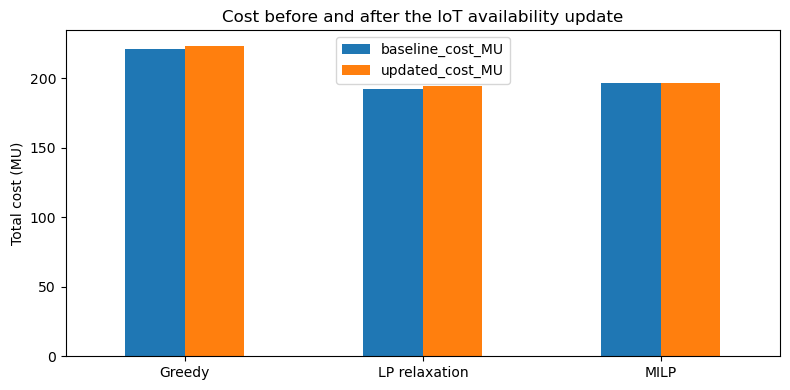

Greedy cost gap over MILP (baseline): 12.63%


In [8]:

comparison = pd.DataFrame([
    ["Greedy", greedy_base["objective"], greedy_event["objective"]],
    ["LP relaxation", lp_base["objective"], lp_event["objective"]],
    ["MILP", milp_base["objective"], milp_event["objective"]],
], columns=["method", "baseline_cost_MU", "updated_cost_MU"])
comparison["change_MU"] = comparison.updated_cost_MU - comparison.baseline_cost_MU
display(comparison)

ax = comparison.set_index("method")[["baseline_cost_MU", "updated_cost_MU"]].plot(
    kind="bar", figsize=(8, 4)
)
ax.set_ylabel("Total cost (MU)")
ax.set_xlabel("")
ax.set_title("Cost before and after the IoT availability update")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

gap = 100*(greedy_base["objective"]-milp_base["objective"])/milp_base["objective"]
print(f"Greedy cost gap over MILP (baseline): {gap:.2f}%")



## 8. Feasibility checks and CSV export

The checks confirm demand satisfaction, source availability, trip capacity, and the maximum trip count. For LP, fractional trips are allowed. For MILP, trip integrality is also checked.


In [9]:

def check_solution(result, source_data, integer_trips=False):
    alloc = result["allocation"]
    if alloc is None:
        return {"feasible": False, "status": result["status"]}
    m = source_data[["source", "availability_t"]].merge(
        alloc[["source", "biomass_collected_t", "trips"]],
        on="source", how="left"
    ).fillna(0)
    checks = {
        "demand": m.biomass_collected_t.sum() >= BIOMASS_REQUIREMENT_T-1e-6,
        "availability": (m.biomass_collected_t <= m.availability_t+1e-6).all(),
        "trip_capacity": (m.biomass_collected_t <= VEHICLE_PAYLOAD_T*m.trips+1e-6).all(),
        "maximum_trips": m.trips.sum() <= MAX_TRIPS+1e-6,
    }
    if integer_trips:
        checks["integer_trips"] = all(abs(v-round(v)) <= 1e-6 for v in m.trips)
    return {"feasible": all(checks.values()), **checks}

checks = pd.DataFrame({
    "Greedy baseline": check_solution(greedy_base, data),
    "LP baseline": check_solution(lp_base, data),
    "MILP baseline": check_solution(milp_base, data, True),
    "Greedy IoT": check_solution(greedy_event, updated_data),
    "LP IoT": check_solution(lp_event, updated_data),
    "MILP IoT": check_solution(milp_event, updated_data, True),
}).T
display(checks)

data.to_csv("biomass_source_data_baseline.csv", index=False)
updated_data.to_csv("biomass_source_data_iot_update.csv", index=False)
baseline_summary.to_csv("baseline_results.csv", index=False)
event_summary.to_csv("iot_update_results.csv", index=False)
comparison.to_csv("baseline_vs_iot_comparison.csv", index=False)
print("CSV result files exported.")


,feasible,demand,availability,trip_capacity,maximum_trips,integer_trips
Greedy baseline,True,True,True,True,True,NaN
LP baseline,True,True,True,True,True,NaN
MILP baseline,True,True,True,True,True,True
Greedy IoT,True,True,True,True,True,NaN
LP IoT,True,True,True,True,True,NaN
MILP IoT,True,True,True,True,True,True


CSV result files exported.



## 9. Interpretation cautions

- Greedy is a transparent baseline, not an exact method. Its source-by-source allocation can create partly loaded trips.
- LP relaxes the integer trip requirement. It is a lower bound, not an executable trip plan.
- MILP accounts for whole trips and can jointly select source quantities and trip counts.
- The difference in this example demonstrates the effect of integer trip costs and allocation decisions. It does not establish that MILP always outperforms every greedy heuristic.
- The IoT experiment changes one availability estimate and re-solves the same model. It illustrates event-triggered re-optimization.
- A stronger greedy heuristic could use look-ahead or local improvement. That would be a different baseline and should be defined explicitly.
- A Genetic Algorithm may be mentioned as an alternative for larger formulations. It is not implemented or compared here.
